In [16]:
import numpy as np

# --- Constantes et Paramètres ---

# Paramètres de l'âge pour le vecteur
AGE_DEBUT = 25
AGE_FIN_EXCLU = 66
# Note: np.arange(25, 66) crée les âges de 25 à 65 inclus.

# Paramètres de la formule de Makeham simplifiée (q_x = A * exp(B * (x - C)))
PARAM_A = 0.0001
PARAM_B = 0.1
PARAM_C = 25

# --- Création des Vecteurs et Calculs Actuariels ---

# 1. Vecteur des âges (x)
# Les âges vont de 25 à 65 ans.
ages = np.arange(AGE_DEBUT, AGE_FIN_EXCLU)

# 2. Table de mortalité (Probabilité de décès avant l'âge suivant, qx)
# Formule Makeham simplifiée: qx = 0.0001 * exp(0.1 * (x - 25))
probabilite_deces_qx = PARAM_A * np.exp(PARAM_B * (ages - PARAM_C))

# 3. Probabilités de survie annuelles (px)
# Relation fondamentale: px = 1 - qx
probabilite_survie_px = 1 - probabilite_deces_qx

# 4. Probabilité de survie cumulative
# C'est la probabilité de survivre du premier âge (25) jusqu'à chaque âge x.
# Calculée par le produit cumulé des probabilités de survie annuelles.
probabilite_survie_cumul = np.cumprod(probabilite_survie_px)

# --- Affichage du Résultat ---

# La dernière valeur du vecteur cumulé (indice -1) est la probabilité
# de survivre de l'âge initial (25) jusqu'à l'âge final (65).
survie_25_a_65 = probabilite_survie_cumul[-1]

print(f"Probabilité de survie de {AGE_DEBUT} ans jusqu'à {AGE_FIN_EXCLU - 1} ans : {survie_25_a_65:.2%}")
# Output: Probabilité de survie de 25 ans jusqu'à 65 ans : 98.73%

Probabilité de survie de 25 ans jusqu'à 65 ans : 94.51%


In [12]:
import pandas as pd

# --- Constantes et Paramètres ---

# Définition des bornes des tranches d'âge et de leurs étiquettes
TRANCHES_BINS = [0, 40, 60, 100]
TRANCHES_LABELS = ['<40', '40-60', '>60']

# Seuil de Prime Moyenne (PM) pour le filtrage
SEUIL_PM_FILTRAGE = 50000

# --- Création du DataFrame (Données Brutes) ---

# Créer un DataFrame (équivalent à une table/feuille Excel)
data_contrats = {
    'id': [1, 2, 3, 4, 5],
    'age': [30, 45, 60, 55, 40],
    'PM': [10000, 50000, 80000, 120000, 25000],
    'TMG': [0.01, 0.02, 0.025, 0.015, 0.01]
}
df_contrats = pd.DataFrame(data_contrats)

# --- Opérations de Filtrage ---

# 1. Filtrer les "gros" contrats (PM > 50 000)
# Utilisation du nom du DataFrame (df_contrats) dans la condition pour la clarté.
condition_gros_contrats = df_contrats['PM'] > SEUIL_PM_FILTRAGE
df_gros_contrats = df_contrats[condition_gros_contrats]

# Afficher le nombre de contrats filtrés
nombre_gros_contrats = len(df_gros_contrats)
print(f"Nombre de gros contrats (PM > {SEUIL_PM_FILTRAGE:,}): {nombre_gros_contrats}")

# --- Opérations de Groupement et Agrégation ---

# 2. Créer la colonne 'tranche_age' en catégorisant la colonne 'age'
# pd.cut segmente les données en intervalles spécifiés.
df_contrats['tranche_age'] = pd.cut(
    df_contrats['age'],
    bins=TRANCHES_BINS,
    labels=TRANCHES_LABELS,
    right=False  # Les intervalles sont [borne_inf, borne_sup[ (sauf la dernière)
)

# 3. Calculer la Prime Moyenne (PM) par tranche d'âge
# groupement par la nouvelle colonne 'tranche_age' et calcul de la moyenne de 'PM'.
pm_moyenne_par_tranche = df_contrats.groupby('tranche_age')['PM'].mean()

# Afficher le résultat du calcul
print("\nPrime Moyenne par Tranche d'Âge :\n")
print(pm_moyenne_par_tranche)

# Output partiel :
# tranche_age
# <40      17500.0
# 40-60    85000.0
# >60      80000.0
# Name: PM, dtype: float64

Nombre de gros contrats (PM > 50,000): 2

Prime Moyenne par Tranche d'Âge :

tranche_age
<40      10000.0
40-60    65000.0
>60      80000.0
Name: PM, dtype: float64


C:\Users\FabriceBM\AppData\Local\Temp\ipykernel_756\2804475102.py:47: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pm_moyenne_par_tranche = df_contrats.groupby('tranche_age')['PM'].mean()


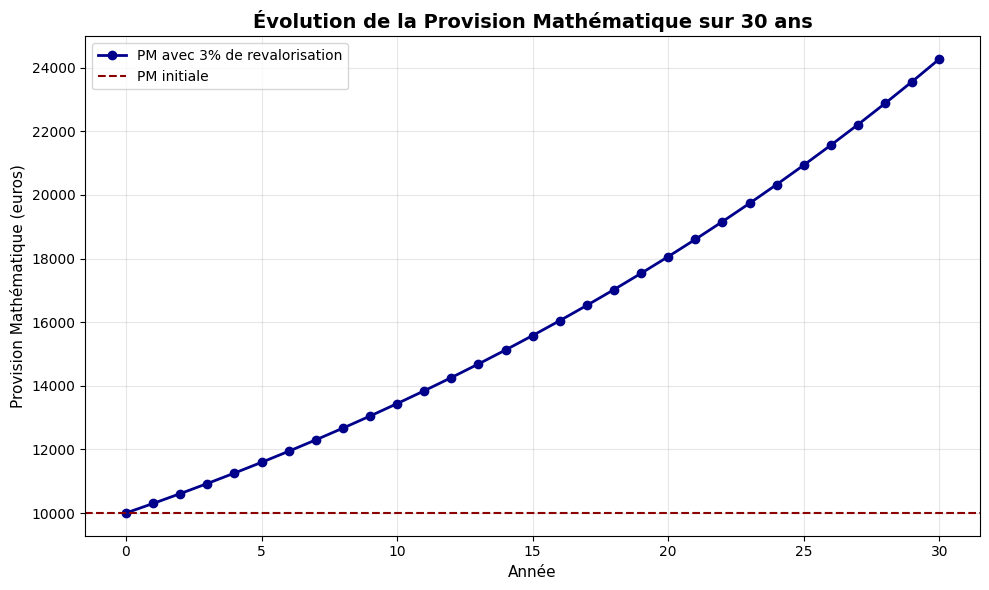

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# --- Constantes et Paramètres de l'Étude ---

# Paramètres de l'évolution (taux d'intérêt composé)
PM_INITIAL = 10000        # Prime initiale (Provision Mathématique à t=0)
TAUX_REVALORISATION = 0.03 # 3%
NOMBRE_ANNEES = 30         # Durée de l'étude (de 0 à 30 ans inclus)

# Paramètres du Graphique
COULEUR_COURBE = 'darkblue'
COULEUR_LIGNE_REF = 'darkred'
LARGEUR_LIGNE = 2
TAILLE_POLICE_AXE = 11
TAILLE_POLICE_TITRE = 14
NOM_FICHIER_SORTIE = 'evolution_provision_mathematique.png'

# --- 1. Calcul des Données ---

# Vecteur des années, de 0 à NOMBRE_ANNEES (30) inclus.
annees = np.arange(0, NOMBRE_ANNEES + 1)

# Calcul de l'évolution de la Prime/Provision Mathématique (capitalisation)
# Formule: PM(t) = PM_INITIAL * (1 + taux)^t
provision_mathematique = PM_INITIAL * (1 + TAUX_REVALORISATION) ** annees

# --- 2. Création et Mise en Forme du Graphique ---

# Initialiser la figure avec une taille spécifique
fig, ax = plt.subplots(figsize=(10, 6))

# Tracer l'évolution de la Provision Mathématique
ax.plot(
    annees,
    provision_mathematique,
    marker='o',
    linestyle='-',
    linewidth=LARGEUR_LIGNE,
    color=COULEUR_COURBE,
    label=f'PM avec {TAUX_REVALORISATION:.0%} de revalorisation'
)

# Ajouter une ligne horizontale pour la valeur initiale (PM_INITIAL)
ax.axhline(
    y=PM_INITIAL,
    color=COULEUR_LIGNE_REF,
    linestyle='--',
    label='PM initiale'
)

# Configuration des Labels et Titres
ax.set_xlabel('Année', fontsize=TAILLE_POLICE_AXE)
ax.set_ylabel('Provision Mathématique (euros)', fontsize=TAILLE_POLICE_AXE)
ax.set_title(
    f"Évolution de la Provision Mathématique sur {NOMBRE_ANNEES} ans",
    fontsize=TAILLE_POLICE_TITRE,
    fontweight='bold'
)

# Affichage de la Légende et de la Grille
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

# Ajuster automatiquement les paramètres de la figure pour un affichage serré
plt.tight_layout()

# --- 3. Sauvegarde et Affichage ---

# Sauvegarder le graphique en haute résolution
plt.savefig(NOM_FICHIER_SORTIE, dpi=300)

# Afficher le graphique
plt.show()